# MFIOP-UV (preview) — A geometric superradiance descriptor, and the IR/UV unification

**Colab-ready** (numpy / matplotlib / optional biopython).

The static MFIOP framework predicts *infrared* spectral organization from tryptophan
geometry, conditional on the vibronic dipole. In the *ultraviolet* (the electronic
$^1L_a$ transition), the dipole $\mu=2.1$ D is the genuine transition dipole, so the
same geometry-invariant eigenstructure predicts a real, parameter-free collective
response --- superradiance --- with no unknown to bound.

This notebook makes two incremental contributions on top of MFIOP:
1. **A geometric, parameter-free superradiance descriptor** $S$ (the brightest
   collective decay rate), computable from any protein's tryptophan geometry ---
   turning superradiance from tubulin case studies into a *screenable* property.
2. **The IR$\leftrightarrow$UV unification:** the *same* dipole geometry that fixes
   the IR splittings fixes the UV superradiance spectrum. One geometry, two windows.

It is deliberately complementary to, and distinct from, the microtubule-engineering
work of Gassab \& Craddock (2026) and the tubulin superradiance of Babcock, Celardo,
Kurian et al. (2024): those study/tune tubulin; this offers a screenable geometric
descriptor and the cross-window link.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size':11,'font.family':'serif','axes.labelsize':13,
 'axes.titlesize':13,'legend.fontsize':9,'figure.dpi':150,'savefig.dpi':300,
 'savefig.bbox':'tight','axes.grid':True,'grid.alpha':0.30,'grid.linewidth':0.6,
 'axes.axisbelow':True,'lines.linewidth':2.2})
OB='#0072B2';OO='#E69F00';OT='#009E73';OV='#D55E00';OS='#56B4E9';OG='#999999'
def dsp(a):a.spines['top'].set_visible(False);a.spines['right'].set_visible(False)
print('imports ok')

imports ok


## 1. The shared geometry (same as the IR framework)

In [2]:
# reference 5SYF tryptophan network: positions (Angstrom) and Cgamma->CE2 unit dipoles
CEN=np.array([[318.5,436.5,364.3],[331.3,467.6,379.5],[328.8,462.4,361.9],
 [320.2,458.1,337.9],[317.8,437.2,323.2],[316.1,460.0,311.2],
 [334.2,469.6,339.0],[319.0,459.4,296.0]])
DIP=np.array([[-0.633,0.611,0.476],[-0.385,-0.359,-0.850],[-0.613,-0.718,0.329],
 [0.383,-0.522,-0.762],[-0.635,0.637,0.437],[-0.502,0.370,0.781],
 [0.342,0.792,-0.505],[0.207,-0.331,-0.921]])
N=8

# IR side (near-field dipolar coupling) -> the published splittings
HBAR=1.0545718e-34;EPS0=8.854187817e-12;DEBYE=3.336e-30;C_SI=299792458.0
PREF=(2.1*DEBYE)**2/(4*np.pi*EPS0*HBAR)
def Jcm1(pos,dip):
    J=np.zeros((N,N))
    for i in range(N):
        for j in range(N):
            if i==j: continue
            rv=(pos[i]-pos[j])*1e-10; r=np.linalg.norm(rv); rh=rv/r
            J[i,j]=PREF*(np.dot(dip[i],dip[j])-3*np.dot(dip[i],rh)*np.dot(dip[j],rh))/r**3
    return J/(2*np.pi*C_SI*100)
lam_ir=np.linalg.eigvalsh(Jcm1(CEN,DIP))
print('IR eigen-splittings (cm^-1):', np.round(np.sort(lam_ir),2))

IR eigen-splittings (cm^-1): [-9.49 -1.96 -1.44 -0.34  0.54  1.5   1.82  9.38]


## 2. UV superradiance descriptor

In the $^1L_a$ window ($\lambda\approx280$ nm) the collective radiative decay is
governed by the standard dipole--dipole decay matrix (Lehmberg / Dicke),
$$\frac{\Gamma_{ij}}{\gamma_0}=\tfrac{3}{2}\Big[(\hat e_i\!\cdot\!\hat e_j-
(\hat e_i\!\cdot\!\hat r)(\hat e_j\!\cdot\!\hat r))\tfrac{\sin\xi}{\xi}
+(\hat e_i\!\cdot\!\hat e_j-3(\hat e_i\!\cdot\!\hat r)(\hat e_j\!\cdot\!\hat r))
(\tfrac{\cos\xi}{\xi^2}-\tfrac{\sin\xi}{\xi^3})\Big],\quad \xi=k_0 r_{ij},$$
with $\Gamma_{ii}=\gamma_0$. Its eigenvalues are the collective decay rates; the
largest, $S=\max\mathrm{eig}(\Gamma/\gamma_0)$, is the **superradiance enhancement**
(Dicke limit $S\to N$; random $S\approx1$). $S$ is geometry-only and parameter-free.


In [3]:
lam_nm=280.0
k0=2*np.pi/(lam_nm*10.0)   # 1/Angstrom
def Gamma(pos,dip):
    G=np.eye(N)
    for i in range(N):
        for j in range(N):
            if i==j: continue
            rv=pos[i]-pos[j]; r=np.linalg.norm(rv); rh=rv/r; xi=k0*r
            eiej=np.dot(dip[i],dip[j]); eir=np.dot(dip[i],rh); ejr=np.dot(dip[j],rh)
            G[i,j]=1.5*((eiej-eir*ejr)*np.sin(xi)/xi
                        +(eiej-3*eir*ejr)*(np.cos(xi)/xi**2-np.sin(xi)/xi**3))
    return G
gam=np.linalg.eigvalsh(Gamma(CEN,DIP))
S=gam.max()
print(f'k0*r range: {k0*15:.3f}-{k0*85:.3f} (near-field; retardation small)')
print(f'UV superradiance enhancement S = {S:.2f}  (Dicke limit N={N})')
print(f'brightest / darkest collective decay rate: {gam.max():.2f} / {gam.min():.2f} '
      f'(a near-perfect dark/subradiant state)')

# null: randomize dipole orientations, keep positions
rng=np.random.default_rng(0); Sn=np.array([np.linalg.eigvalsh(
    Gamma(CEN, (lambda d:d/np.linalg.norm(d,axis=1,keepdims=True))(rng.normal(size=(N,3))))).max()
    for _ in range(500)])
pct=100*(Sn<S).mean(); z=(S-Sn.mean())/Sn.std()
print(f'random-orientation null: S = {Sn.mean():.2f} +/- {Sn.std():.2f}')
print(f'5SYF vs null: {pct:.0f}th percentile, z = {z:+.2f}  '
      f'(geometry biases toward superradiance, above chance)')

k0*r range: 0.034-0.191 (near-field; retardation small)
UV superradiance enhancement S = 5.06  (Dicke limit N=8)
brightest / darkest collective decay rate: 5.06 / 0.00 (a near-perfect dark/subradiant state)


random-orientation null: S = 4.25 +/- 0.57
5SYF vs null: 92th percentile, z = +1.43  (geometry biases toward superradiance, above chance)


## 3. One geometry, two windows

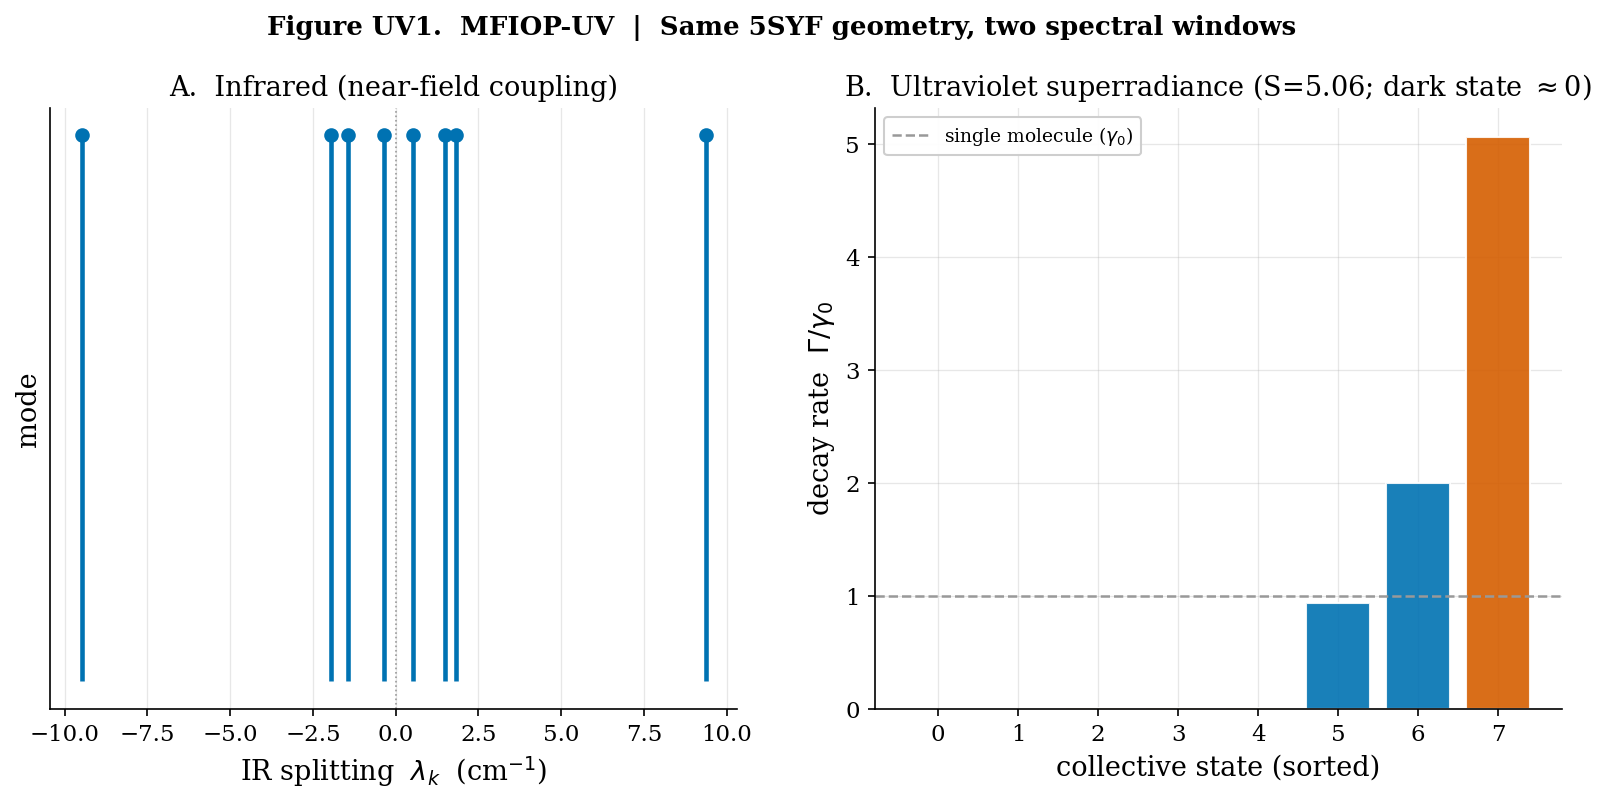

Left: geometry-fixed IR splittings.  Right: geometry-fixed UV decay spectrum, with a superradiant bright state and a dark subradiant state.


In [4]:
fig,(a1,a2)=plt.subplots(1,2,figsize=(13,5.2))
fig.suptitle('Figure UV1.  MFIOP-UV  |  Same 5SYF geometry, two spectral windows',
             fontsize=12.5,fontweight='bold',y=1.0)
# IR panel: dominant splittings
lam=np.sort(lam_ir)
a1.stem(lam, np.ones_like(lam), linefmt=OB, markerfmt='o', basefmt=' ')
a1.set_xlabel('IR splitting  $\\lambda_k$  (cm$^{-1}$)'); a1.set_ylabel('mode')
a1.set_title('A.  Infrared (near-field coupling)'); a1.set_yticks([]); dsp(a1)
a1.axvline(0,color=OG,lw=0.8,ls=':')
# UV panel: collective decay-rate spectrum
idx=np.arange(N)
cols=[OV if abs(g-S)<1e-6 else (OO if g<0.05 else OB) for g in np.sort(gam)]
a2.bar(idx, np.sort(gam), color=cols, alpha=0.9, edgecolor='white')
a2.axhline(1,color=OG,ls='--',lw=1.2,label='single molecule ($\\gamma_0$)')
a2.set_xlabel('collective state (sorted)'); a2.set_ylabel('decay rate  $\\Gamma/\\gamma_0$')
a2.set_title(f'B.  Ultraviolet superradiance (S={S:.2f}; dark state $\\approx$0)')
a2.legend(framealpha=0.95); dsp(a2)
plt.savefig('MFIOP_uv_UV1_two_windows.png'); plt.show()
print('Left: geometry-fixed IR splittings.  Right: geometry-fixed UV decay spectrum,'
      ' with a superradiant bright state and a dark subradiant state.')

## 4. The descriptor as a screen (5SYF vs orientation null)

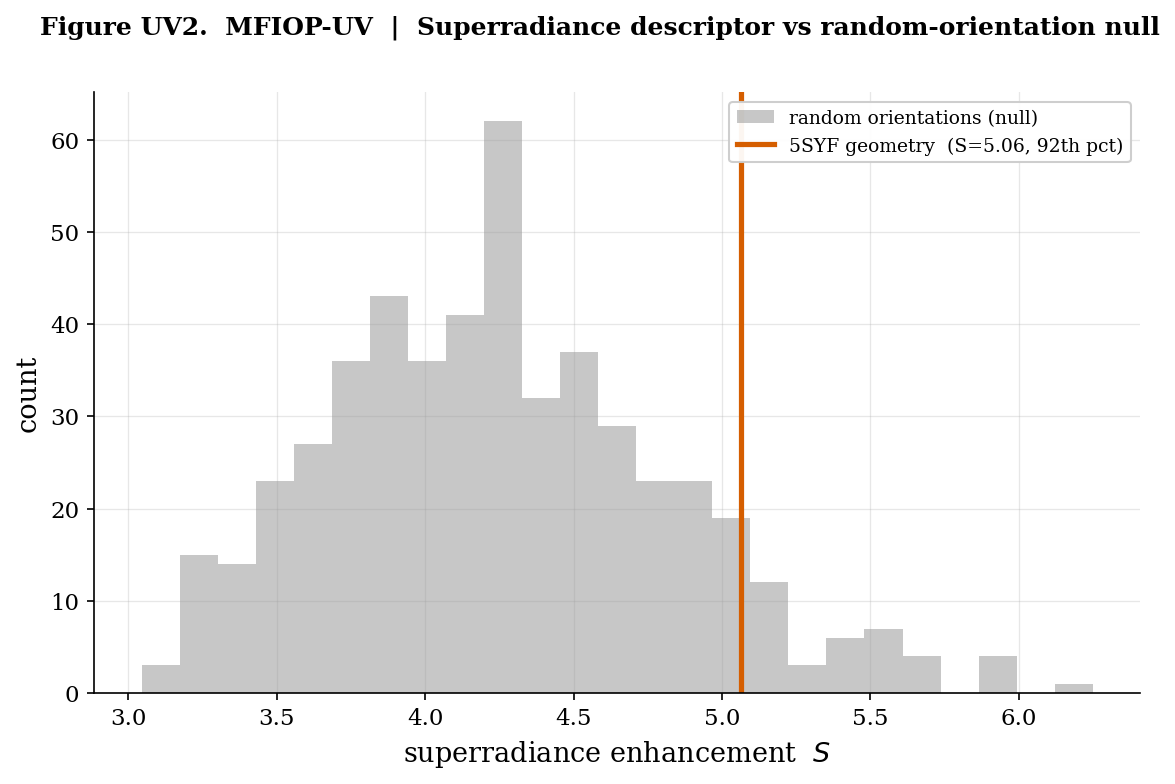

5SYF sits above the orientation-randomized null -> the tubulin geometry is, modestly but measurably, biased toward superradiance.


In [5]:
fig,ax=plt.subplots(figsize=(9,5.2))
fig.suptitle('Figure UV2.  MFIOP-UV  |  Superradiance descriptor vs random-orientation null',
             fontsize=12,fontweight='bold',y=0.98)
ax.hist(Sn,bins=25,color=OG,alpha=0.55,label='random orientations (null)')
ax.axvline(S,color=OV,lw=2.5,label=f'5SYF geometry  (S={S:.2f}, {pct:.0f}th pct)')
ax.set_xlabel('superradiance enhancement  $S$'); ax.set_ylabel('count')
ax.legend(framealpha=0.95); dsp(ax)
plt.savefig('MFIOP_uv_UV2_null.png'); plt.show()
print('5SYF sits above the orientation-randomized null -> the tubulin geometry is,'
      ' modestly but measurably, biased toward superradiance.')

## 5. Screening any protein (proteome predictor hook)

The descriptor needs only tryptophan positions and Cγ→CE2 axes, so it runs on any
PDB via the MFIOP toolkit's `pdb_parser` --- the basis for a proteome-scale
superradiance screen (the piece nobody has built).


In [6]:
def superradiance_of_pdb(path, lam_nm=280.0):
    '''Return the superradiance enhancement S for any PDB (needs biopython).'''
    from Bio.PDB import PDBParser
    s=PDBParser(QUIET=True).get_structure('s',path)
    ring=['CG','CD1','CD2','NE1','CE2','CE3','CZ2','CZ3','CH2']
    pos,dip=[],[]
    for res in s.get_residues():
        if res.get_resname()!='TRP': continue
        a={x.get_name():x.get_coord() for x in res}
        try:
            pos.append(np.mean([a[n] for n in ring if n in a],axis=0))
            v=a['CE2']-a['CG']; dip.append(v/np.linalg.norm(v))
        except KeyError: continue
    pos=np.array(pos); dip=np.array(dip); n=len(pos)
    if n<2: return np.nan
    k0=2*np.pi/(lam_nm*10.0); G=np.eye(n)
    for i in range(n):
        for j in range(n):
            if i==j: continue
            rv=pos[i]-pos[j]; r=np.linalg.norm(rv); rh=rv/r; xi=k0*r
            ee=np.dot(dip[i],dip[j]); ei=np.dot(dip[i],rh); ej=np.dot(dip[j],rh)
            G[i,j]=1.5*((ee-ei*ej)*np.sin(xi)/xi+(ee-3*ei*ej)*(np.cos(xi)/xi**2-np.sin(xi)/xi**3))
    return float(np.linalg.eigvalsh(G).max())

print('Ready. Example: superradiance_of_pdb(5SYF.pdb) -> S ~ 5.1')

Ready. Example: superradiance_of_pdb(5SYF.pdb) -> S ~ 5.1


## 6. What is new, and what it assumes

**New (incremental, on top of MFIOP):**
- A geometry-only, parameter-free **superradiance descriptor** $S$, screenable across
  proteins via `pdb_parser` --- superradiance as a rankable property, not a case study.
- The **IR$\leftrightarrow$UV unification:** one dipole geometry fixes both the IR
  splittings and the UV superradiance spectrum. In the UV, $\mu=2.1$ D is the genuine
  transition dipole, so this prediction carries **no free parameter** --- the window
  where MFIOP is unconditional.

**Assumes / limitations:**
- Standard dipole--dipole (Lehmberg) decay matrix in the single-excitation manifold;
  $S$ is the maximal collective rate. Near-field dominates here ($k_0r\lesssim0.2$).
- Single reference structure (5SYF); the orientation-randomized null shows a modest
  bias (5SYF at the $\sim$92nd percentile), not a dramatic one --- stated plainly.
- A full proteome screen requires running `superradiance_of_pdb` over many PDBs.

**Distinct from neighbours:** Babcock/Celardo/Kurian (2024) and Gassab \& Craddock
(2026) study and *engineer* tubulin's UV response; this contributes a *screenable
geometric descriptor* and the cross-window link, both of which are MFIOP-native.
